# Life & annuity pricing and reserving: walkthrough

This notebook walks through the model end to end, the way a pricing actuary would build it up:

1. **Mortality**: load SOA tables (2017 CSO select & ultimate, 2012 IAM + Scale G2)
2. **Validate the engine** against ALTAM's Standard Ultimate Survival Model
3. **Price a 20-year term policy** to a 10% IRR and compute its CRVM reserves
4. **Price a deferred income annuity** and compute its CARVM reserve
5. **Stress-test** interest, mortality, lapse and expense assumptions
6. **Go stochastic**: interest scenarios, a stochastic reserve, and mortality risk for a block

Every number below comes from the `lamodel` package in this repository.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from lamodel import actuarial as act, analysis as an, charts, sensitivity as sens, stochastic as st
from lamodel.tables import cso_2017, iar_2012
from lamodel.term_life import TermAssumptions, TermLife
from lamodel.deferred_annuity import DIAAssumptions, DeferredIncomeAnnuity
from lamodel.validation import susm_check
%matplotlib inline

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from pathlib import Path
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

## 1. Mortality tables

The 2017 CSO is a **select and ultimate** table: a newly underwritten life has lighter mortality than the ultimate
rate for the same attained age, and the advantage wears off over the 25-year select period. Every basis in the model
reduces to one vector of one-year death rates from the issue age.

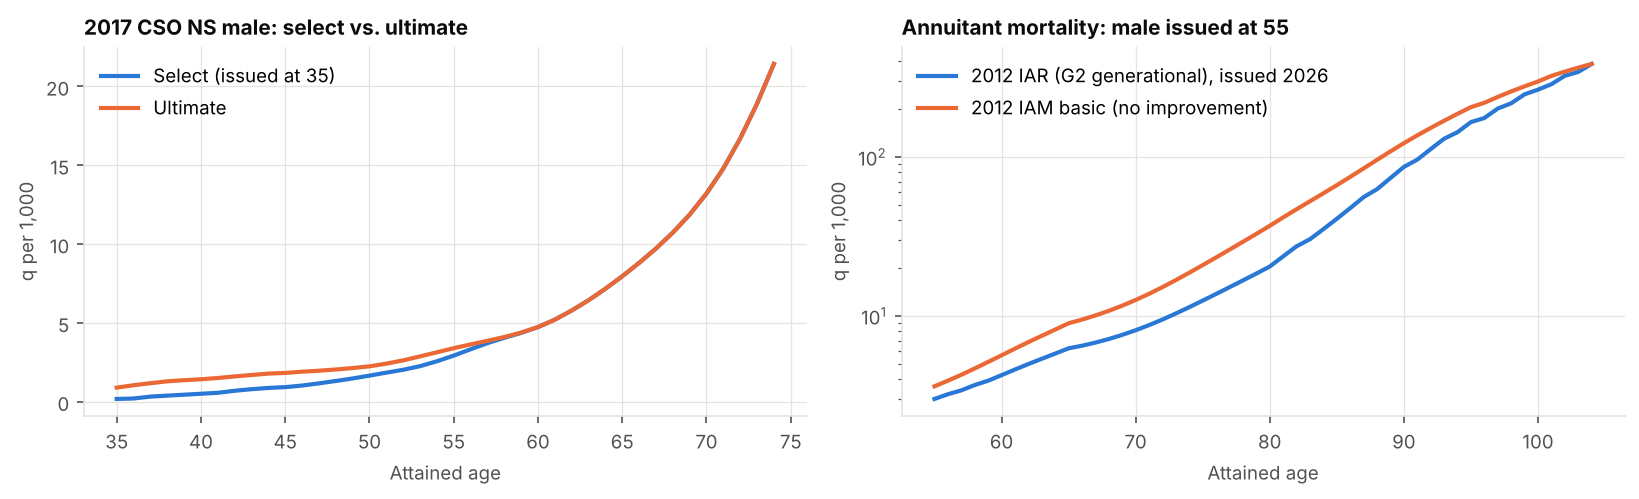

In [2]:
cso = cso_2017("M")
q_select = cso.q(35, 40)
q_ult = cso_2017("M", use_select=False).q(35, 40)
iar = iar_2012("M", issue_year=2026).q(55)
iar_static = iar_2012("M", 2026, improvement_multiplier=0).q(55)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.plot(35 + np.arange(40), q_select * 1000, color=charts.BLUE, label="Select (issued at 35)")
ax.plot(35 + np.arange(40), q_ult * 1000, color=charts.ORANGE, label="Ultimate")
ax.set(title="2017 CSO NS male: select vs. ultimate", xlabel="Attained age", ylabel="q per 1,000"); ax.legend()
ax = axes[1]
ax.plot(55 + np.arange(50), iar[:50] * 1000, color=charts.BLUE, label="2012 IAR (G2 generational), issued 2026")
ax.plot(55 + np.arange(50), iar_static[:50] * 1000, color=charts.ORANGE, label="2012 IAM basic (no improvement)")
ax.set(title="Annuitant mortality: male issued at 55", xlabel="Attained age", ylabel="q per 1,000", yscale="log"); ax.legend()
plt.tight_layout(); plt.show()

## 2. Engine validation against ALTAM

Before pricing anything, the actuarial functions are checked against ALTAM's published Standard Ultimate Survival
Model tables (Makeham: A = 0.00022, B = 2.7e-6, c = 1.124, i = 5%).

In [3]:
susm_check()

,age,l_x model,l_x ALTAM,a-due_x model,a-due_x ALTAM,A_x model,A_x ALTAM
0,20,"100,000.0000","100,000.0000",19.9664,19.9664,0.0492,0.0492
1,50,"98,576.3694","98,576.4000",17.0245,17.0245,0.1893,0.1893
2,60,"96,634.1363","96,634.1000",14.9041,14.9041,0.2903,0.2903
3,65,"94,579.7344","94,579.7000",13.5498,13.5498,0.3548,0.3548


## 3. 20-year level term

The premium is solved so that distributable earnings (statutory profit after tax, less the increase in required
capital) earn exactly the 10% hurdle rate. Reserves are on the statutory basis: 100% 2017 CSO select at 3.5%.

In [4]:
term = TermLife(TermAssumptions()).price()
pd.Series(term.metrics).to_frame("value")

,value
gross_annual_premium,617.2100
premium_per_1000,1.2344
irr,0.1000
pv_de_at_hurdle,-0.0121
profit_margin,-0.0000
breakeven_year,10
peak_reserve_per_1000,5.2604
crvm_method,FPT
valuation_net_premium_per_1000_nlp,0.9012
crvm_alpha_per_1000,0.1739


In [5]:
cols = ["year", "inforce_bop", "premium", "commission", "expenses", "death_claims", "investment_income",
        "increase_in_reserve", "pretax_stat_gain", "distributable_earnings", "crvm_factor_per_1000"]
term.projection[cols].round(2).head(10)

,year,inforce_bop,premium,commission,expenses,death_claims,investment_income,increase_in_reserve,pretax_stat_gain,distributable_earnings,crvm_factor_per_1000
0,1,1.0000,617.2100,555.4900,875.0000,63.0000,-41.2800,0.0000,-929.9000,-674.8200,0.0000
1,2,0.9200,567.7600,28.3900,70.7200,67.6100,22.8700,336.3500,76.2000,99.6400,0.7800
2,3,0.8600,533.6200,26.6800,68.1200,99.8600,38.2200,264.6100,101.8900,114.5000,1.4600
3,4,0.8200,506.8200,25.3400,66.3200,112.0900,50.3000,231.9200,111.3100,116.7300,2.1100
4,5,0.7900,486.4100,24.3200,65.2400,124.1200,61.0000,198.3000,125.7000,127.6100,2.7300
5,6,0.7600,466.8100,23.3400,64.1800,135.0000,70.0600,167.0900,137.9200,136.7500,3.3000
6,7,0.7300,447.9800,22.4000,63.1300,144.8000,77.5900,138.1600,148.1200,144.2800,3.8400
7,8,0.7000,429.8900,21.4900,62.0900,170.6400,83.7100,88.0100,162.7600,155.7600,4.2600
8,9,0.6700,412.4900,20.6200,61.0700,187.1300,87.3500,51.5200,171.2400,162.1200,4.6000
9,10,0.6400,395.7700,19.7900,60.0600,197.5000,89.2000,24.1700,175.5400,165.0000,4.8800


**Where the premium goes.** Since the price is solved to a zero PV of profit at the hurdle, the components below
add to exactly 100% of PV premium. Holding reserves and capital is a *cost*: they earn 5% while the shareholder
requires 10%.

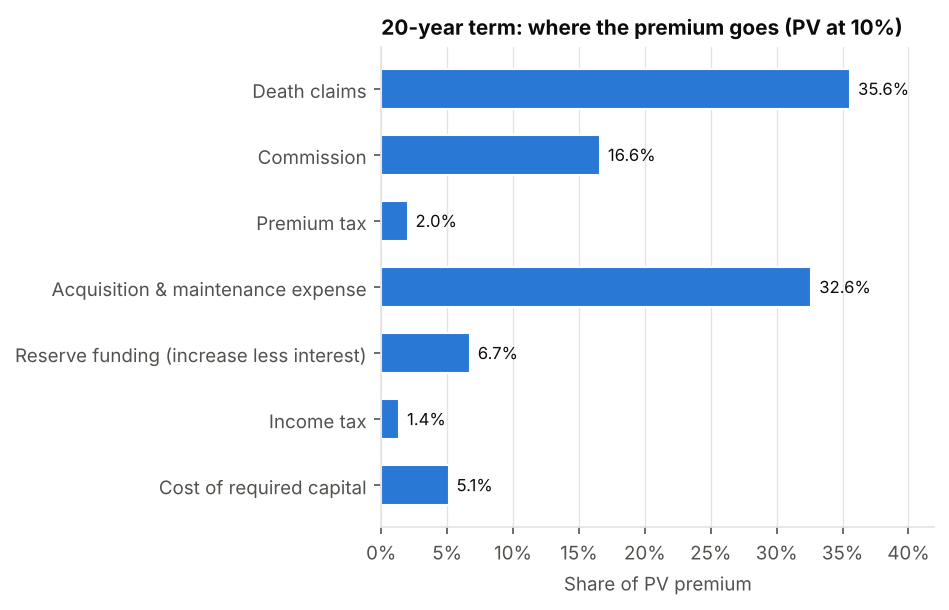

In [6]:
build = an.term_premium_buildup(term)
charts.premium_buildup(build, FIG / "term_buildup.png", "20-year term: where the premium goes (PV at 10%)")
display(Image(FIG / "term_buildup.png"))

**CRVM.** For level term, the expense allowance cap (the 19-payment life premium) does not bind, so CRVM equals
full preliminary term: the first-year net premium is just the one-year term cost and the reserve at the end of year 1
is zero. The recursion $({}_tV + P)(1+i) = q\,b + p\,{}_{t+1}V$ holds year by year (see `tests/`).

NLP premium per $1,000:  0.9012
CRVM alpha / beta:       0.1739 / 0.9545   (FPT)


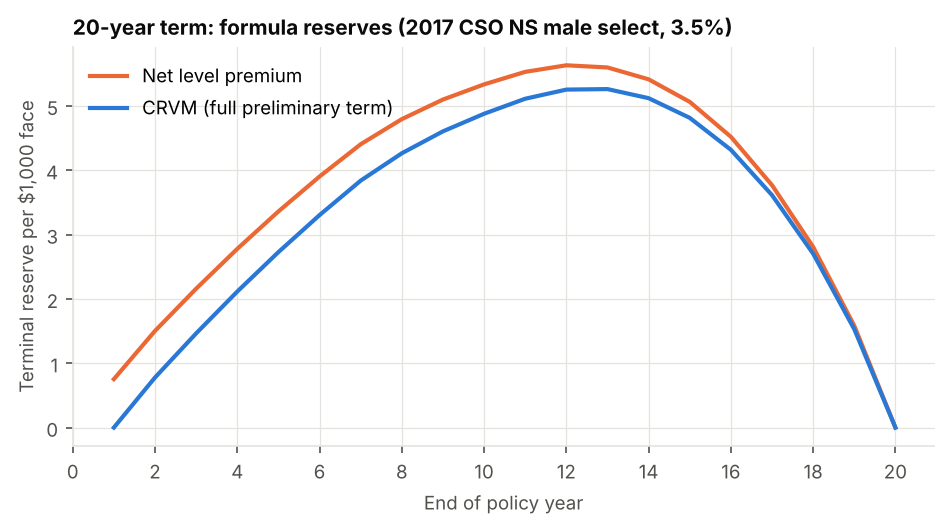

In [7]:
rf = term.reserve_factors
print(f"NLP premium per $1,000:  {rf.nlp_premium * 1000:.4f}")
print(f"CRVM alpha / beta:       {rf.alpha * 1000:.4f} / {rf.beta * 1000:.4f}   ({rf.method})")
display(Image("../outputs/term_reserves.png"))

## 4. Deferred income annuity

A single premium of $100,000 at 55 buys level life income from 65, with return of premium on death before 65.

In [8]:
dia = DeferredIncomeAnnuity(DIAAssumptions()).price()
pd.Series(dia.metrics).to_frame("value")

,value
annual_income,"10,821.2700"
payout_rate,0.1082
irr,0.1000
pv_de_at_hurdle,0.0275
profit_margin,0.0000
breakeven_year,12.0000
initial_reserve,"98,113.6582"
initial_reserve_pct_premium,0.9811
peak_reserve_per_contract,"157,567.6041"
life_expectancy_at_issue_pricing,33.0298


In [9]:
an.dia_premium_buildup(dia)

,component,pv,pct_of_premium
0,Life income payments,"86,323.0318",0.8632
1,Return-of-premium death benefits,"3,073.8641",0.0307
2,Commission,"3,000.0000",0.0300
3,Acquisition & maintenance expense,"1,673.7874",0.0167
4,"Margin for tax, capital cost and profit","5,929.3167",0.0593
5,Single premium,"100,000.0000",1.0000


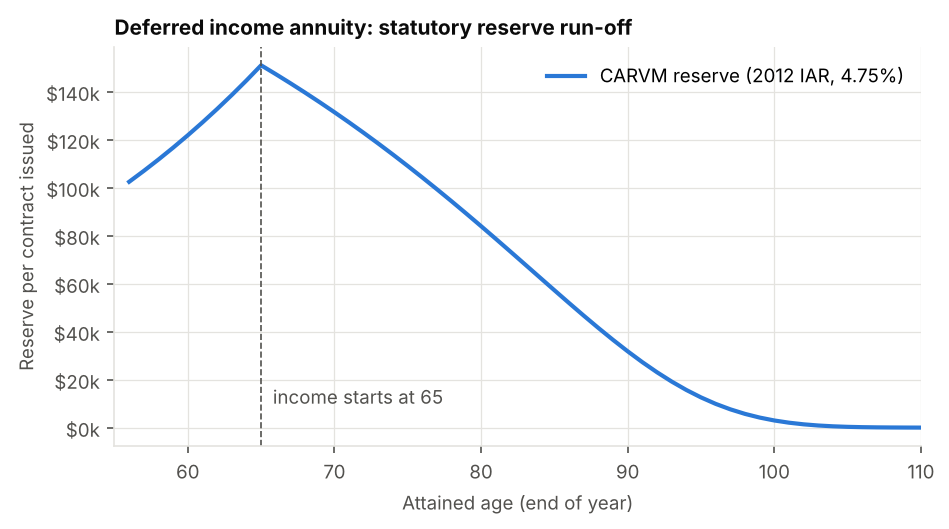

In [10]:
display(Image('../outputs/dia_reserves.png'))

## 5. Sensitivities

Each shock is applied with the price held at base (impact on profitability) and with the price re-solved
(what the shock would cost the customer).

In [11]:
sens.run_term(TermAssumptions())[['scenario', 'irr_at_base_premium', 'repriced_annual_premium', 'premium_change_pct']]

,scenario,irr_at_base_premium,repriced_annual_premium,premium_change_pct
0,Base,0.1000,617.2100,0.0000
1,Earned rate -100bp,0.0889,640.2900,0.0374
2,Earned rate +100bp,0.1107,594.5700,-0.0367
3,Valuation rate -50bp,0.0997,617.9500,0.0012
4,Valuation rate +50bp,0.1004,616.4700,-0.0012
5,Mortality 90%,0.1118,591.5400,-0.0416
6,Mortality 110%,0.0873,642.8700,0.0416
7,Mortality 120%,0.0735,668.5200,0.0831
8,Lapses 75%,0.1013,614.5000,-0.0044
9,Lapses 125%,0.0982,621.0800,0.0063


In [12]:
sens.run_dia(DIAAssumptions())[['scenario', 'profit_margin_at_base_payout', 'initial_reserve_pct_premium', 'repriced_payout_rate']]

,scenario,profit_margin_at_base_payout,initial_reserve_pct_premium,repriced_payout_rate
0,Base,0.0000,0.9811,0.1082
1,Earned rate -100bp,-0.0902,0.9811,0.0958
2,Earned rate +100bp,0.0902,0.9811,0.1240
3,Valuation rate -50bp,-0.0264,1.0790,0.1043
4,Valuation rate +50bp,0.0241,0.8940,0.1121
5,Mortality 90% (longevity),-0.0045,0.9811,0.1075
6,Mortality 110%,0.0043,0.9811,0.1089
7,No mortality improvement,0.0215,0.9811,0.1117
8,150% Scale G2 improvement,-0.0088,0.9811,0.1069
9,Expenses 110%,-0.0008,0.9811,0.1081


Term life is a **mortality and expense** business, and the deferred annuity is a **spread** business: 100bp of earned
rate moves annuity profit by about 9% of premium, roughly ten times any mortality shock.

Note that several annuity IRRs come back blank: when later-year earnings turn negative the cash flows change sign
more than once and the IRR is not unique, so the annuity is judged on PV of profit instead.

## 6. Stochastic analysis

### Interest scenarios
A Vasicek short-rate model drives the 10-year new-money yield; the portfolio earned rate rolls toward new money as
10% of assets reinvest each year.

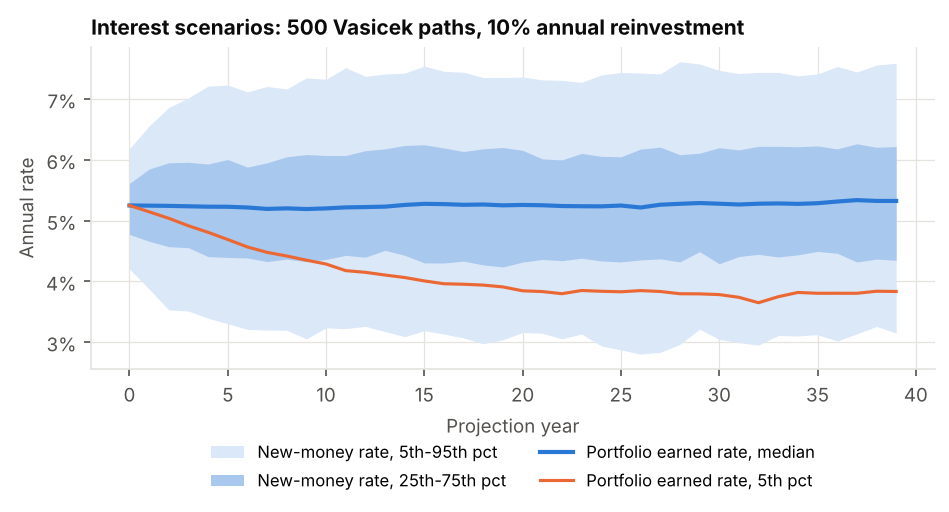

In [13]:
earned, new_money = an.interest_scenarios(0.0525, len(dia.projection), 500, seed=2026)
charts.interest_fan(earned, new_money, FIG / "fan.png")
display(Image(FIG / "fan.png"))

In [14]:
pv = an.dia_stochastic_profit(dia, earned)
pd.Series(st.summarise(pv / 1e5)).to_frame("% of premium")

,% of premium
mean,-0.0012
std,0.0322
p05,-0.0519
p50,-0.0002
p95,0.0493
prob_loss,0.5040
var_995_loss,0.0761
cte70_loss,0.0394
cte98_loss,0.0717


### Stochastic reserve
The **greatest present value of accumulated deficiencies** (GPVAD) is the starting asset amount that keeps the
asset balance non-negative throughout a scenario. Its CTE70 across scenarios is the stochastic reserve, the mechanics
behind VM-20 and VM-22. For the annuity it sits **above** the formula CARVM reserve, because reinvestment risk is
real. For term it sits well **below** CRVM: the formula basis is conservative, which is why principles-based
reserving released term reserves.

In [15]:
cmp_dia = an.dia_reserve_comparison(dia, earned, years=range(0, 41, 5))
cmp_dia.round(0)

,duration,attained_age,carvm,deterministic,stochastic_cte70,stochastic_cte98
0,0,55,"98,114.0000","92,248.0000","101,867.0000","110,998.0000"
1,5,60,"123,988.0000","118,909.0000","127,251.0000","134,861.0000"
2,10,65,"157,568.0000","154,145.0000","160,769.0000","166,657.0000"
3,15,70,"141,980.0000","140,361.0000","145,250.0000","149,543.0000"
4,20,75,"123,617.0000","123,727.0000","127,014.0000","129,877.0000"
5,25,80,"102,849.0000","104,451.0000","106,408.0000","108,107.0000"
6,30,85,"80,624.0000","83,312.0000","84,322.0000","85,211.0000"
7,35,90,"59,824.0000","63,017.0000","63,469.0000","63,871.0000"
8,40,95,"43,413.0000","46,585.0000","46,768.0000","46,935.0000"


### Mortality risk for a block of term policies
Process risk (random timing of deaths) diversifies as the block grows, roughly as $1/\sqrt{N}$. Parameter risk
(the true mortality level differs from the assumption) does not, so it dominates for large blocks. That is why
experience studies and credibility matter more than block size.

In [16]:
risk = an.term_mortality_risk(term, block_sizes=(1_000, 10_000, 100_000), n_sims=2_000)
risk[["policies", "risk", "sd_pct_premium", "var995_pct_premium"]]

,policies,risk,sd_pct_premium,var995_pct_premium
0,1000,Process only,0.1027,0.3168
1,1000,Process + parameter (10% level sd),0.1028,0.2983
2,10000,Process only,0.0315,0.0934
3,10000,Process + parameter (10% level sd),0.0402,0.1114
4,100000,Process only,0.0101,0.0256
5,100000,Process + parameter (10% level sd),0.0282,0.0842


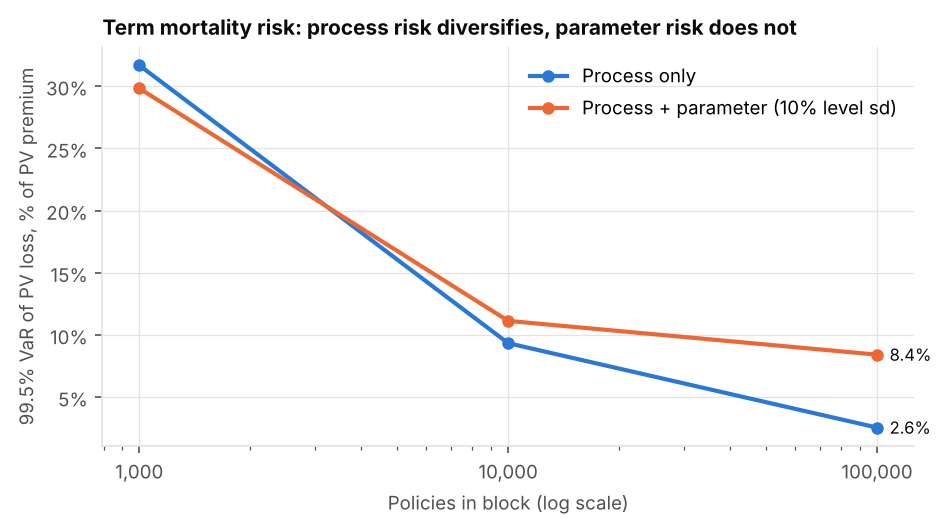

In [17]:
charts.mortality_risk(risk, FIG / "mort.png")
display(Image(FIG / "mort.png"))

---
The full run (`python run_model.py`) writes every table here, plus rate cards and sensitivity grids, to `outputs/`
as CSVs, a formatted Excel workbook and charts. See `docs/methodology.md` for the formulas.